# AI/GenAI/ML Mentions in Investor PDFs (2021–2026)

This notebook performs a reproducible computational scan of PDF investor materials and reports, using text extraction pipeline. It identifies documents that contain AI-related terminology and quantifies yearly mention rates overall and by company.

**Input:** `data/metadata.json` with fields `{path, company, year, category}`.

Eligibility is assigned when at least one predefined AI-related pattern is found (case-insensitive regex with lexical variants, abbreviations, and hyphenation forms).

In [1]:
from pathlib import Path
import json
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import fitz
from pypdf import PdfReader
import pdfplumber

In [2]:
ROOT = Path.cwd()
METADATA_PATH = ROOT / 'data' / 'metadata.json'

with METADATA_PATH.open('r', encoding='utf-8') as f:
    meta = json.load(f)

df_meta = pd.DataFrame(meta)
df_meta['abs_path'] = df_meta['path'].map(lambda p: ROOT / p)
df_meta['year'] = df_meta['year'].astype(int)

SECTOR_MAP = {
    'Nestlé S.A.': 'FMCG',
    'Unilever PLC': 'FMCG',
    'Procter & Gamble Co.': 'FMCG',
    'Colgate-Palmolive Co.': 'FMCG',
    'PepsiCo, Inc.': 'FMCG',
    'Ceconomy AG': 'Hardlines',
    'Electrolux AB': 'Hardlines',
    'The Home Depot, Inc.': 'Hardlines',
    'Kingfisher plc': 'Hardlines',
    'Whirlpool Corporation': 'Hardlines',
}
df_meta['sector'] = df_meta['company'].map(SECTOR_MAP).fillna('Unknown')

print(f'Documents in metadata: {len(df_meta)}')
df_meta.head()

Documents in metadata: 228


,path,company,year,category,abs_path,sector
0,data/Ceconomy/CECONOMY AG_CECONOMY AG updates ...,Ceconomy AG,2021,investor news,/Users/przemyslawniedziela/Desktop/ai_shift/da...,Hardlines
1,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,2024,annual reports,/Users/przemyslawniedziela/Desktop/ai_shift/da...,Hardlines
2,data/Ceconomy/CECONOMY Results Presentation Q4...,Ceconomy AG,2024,results presentations,/Users/przemyslawniedziela/Desktop/ai_shift/da...,Hardlines
3,data/Ceconomy/ceconomy_ag_annual_report_2023_2...,Ceconomy AG,2024,investor news,/Users/przemyslawniedziela/Desktop/ai_shift/da...,Hardlines
4,data/Ceconomy/ceconomy_annual_report_2022_23-1...,Ceconomy AG,2023,investor news,/Users/przemyslawniedziela/Desktop/ai_shift/da...,Hardlines


In [3]:
df_meta.shape

(228, 6)

In [4]:
TERM_PATTERNS = {
    'ai': r'\bartificial intelligence\b|\bai\b|\bai[- ]?(enabled|driven|powered|based|assisted|augmented)\b',
    'genai': r'\bgenerative ai\b|\bgen\s*ai\b|\bgenai\b|\bai[- ]generated\b',
    'machine_learning': r'\bmachine learning\b|\bml\b|\bmachine[- ]learn(ing|ed)\b|\bml[- ]?(enabled|driven|based)\b',
    'deep_learning': r'\bdeep learning\b|\bdeep[- ]learn(ing|ed)\b',
    'llm': r'\blarge language model(s)?\b|\bllm(s)?\b|\bfoundation model(s)?\b|\bgpt[- ]?[2345]\b|\btransformer model(s)?\b',
    'nlp': r'\bnatural language processing\b|\bnlp\b|\blanguage model(s)?\b',
    'computer_vision': r'\bcomputer vision\b|\bvision model(s)?\b|\bimage recognition\b',
    'neural_networks': r'\bneural network(s)?\b|\bneural net(s)?\b|\bcnn(s)?\b|\brnn(s)?\b',
    'data_engineering': r'\bdata engineering\b|\bdata pipeline(s)?\b|\betl\b|\belt\b|\bdata platform(s)?\b|\bdata architecture\b|\bdata lake(s)?\b|\bdata warehouse(s)?\b',
    'mlops': r'\bmlops\b|\bmodel ops\b|\bmodel operations\b|\bmodel deployment\b|\bmodel monitoring\b',
    'training_inference': r'\bmodel training\b|\binference\b|\bfine[- ]?tuning\b|\bprompt engineering\b',
    'adjacent_analytics': r'\bpredictive analytics\b|\bpredictive model(s|ling)?\b|\badvanced analytics\b|\balgorithmic\b'
}

COMPILED_PATTERNS = {k: re.compile(v, flags=re.IGNORECASE) for k, v in TERM_PATTERNS.items()}

def clean_text(text: str) -> str:
    if not text:
        return ''
    text = re.sub(r'-\n', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [5]:
def extract_text_pymupdf(pdf_path: Path) -> str:
    chunks = []
    with fitz.open(pdf_path) as doc:
        for page in doc:
            chunks.append(page.get_text('text') or '')
    return '\n'.join(chunks)


def extract_text_pypdf(pdf_path: Path) -> str:
    chunks = []
    reader = PdfReader(str(pdf_path))
    for page in reader.pages:
        chunks.append(page.extract_text() or '')
    return '\n'.join(chunks)


def extract_text_pdfplumber(pdf_path: Path) -> str:
    chunks = []
    with pdfplumber.open(str(pdf_path)) as pdf:
        for page in pdf.pages:
            chunks.append(page.extract_text() or '')
    return '\n'.join(chunks)


def robust_extract_text(pdf_path: Path):
    """
    Returns: (text, engine_name, status)
    status in {'ok','failed'}
    """
    engines = [
        ('pymupdf', extract_text_pymupdf),
        ('pypdf', extract_text_pypdf),
        ('pdfplumber', extract_text_pdfplumber),
    ]

    errors = []
    for name, fn in engines:
        try:
            txt = clean_text(fn(pdf_path))
            if txt and len(txt) > 50:
                return txt, name, 'ok'
            errors.append(f'{name}:empty')
        except Exception as exc:
            errors.append(f'{name}:{type(exc).__name__}')

    return '', ';'.join(errors), 'failed'

In [6]:
ANALYTICAL_PREDICTIVE_PATTERNS = {
    'machine_learning': r'\bmachine learning\b|\bml\b',
    'neural_networks': r'\bneural network(s)?\b|\bneural net(s)?\b|\bcnn(s)?\b|\brnn(s)?\b',
    'predictive_analytics': r'\bpredictive analytics\b|\bpredictive model(s|ling)?\b',
    'forecasting': r'\bdemand forecasting\b|\bforecasting model(s)?\b|\btime[- ]series forecast(ing)?\b',
    'optimization_scheduling': r'\balgorithmic scheduling\b|\boptimization\b|\boptimisation\b|\brouting optimization\b'
}

GENERATIVE_AGENTIC_PATTERNS = {
    'generative_ai': r'\bgenerative ai\b|\bgen\s*ai\b|\bgenai\b|\bai[- ]generated\b|\bgenerative model(s)?\b',
    'llm_foundation': r'\blarge language model(s)?\b|\bllm(s)?\b|\bfoundation model(s)?\b|\bgpt[- ]?[2345]\b|\bchatgpt\b|\bclaude\b|\bgemini\b|\blama\b|\bllama\b',
    'copilot_assistant': r'\bcopilot(s)?\b|\bai assistant(s)?\b|\bvirtual assistant(s)?\b|\bdigital assistant(s)?\b|\bchatbot(s)?\b',
    'agentic_autonomous': r'\bagentic\b|\bagentic ai\b|\bautonomous workflow(s)?\b|\bautonomous agent(s)?\b|\bai agent(s)?\b|\bagent[- ]based\b|\bmulti[- ]agent\b',
    'rag_retrieval': r'\bretrieval[- ]augmented generation\b|\brag\b|\bgrounded generation\b|\bvector database(s)?\b',
    'multimodal_generation': r'\bmultimodal\b|\btext[- ]to[- ]image\b|\btext[- ]to[- ]video\b|\bimage generation\b|\bdiffusion model(s)?\b|\bsynthetic content\b',
    'prompt_orchestration': r'\bprompt engineering\b|\bprompt design\b|\borchestration layer\b|\bworkflow orchestration\b|\btool[- ]using agent(s)?\b|\bfunction calling\b'
}

COMPILED_LEGACY = {k: re.compile(v, flags=re.IGNORECASE) for k, v in ANALYTICAL_PREDICTIVE_PATTERNS.items()}
COMPILED_GENERATIVE = {k: re.compile(v, flags=re.IGNORECASE) for k, v in GENERATIVE_AGENTIC_PATTERNS.items()}

def detect_mentions(text: str, compiled_patterns: dict):
    counts = {}
    for label, pattern in compiled_patterns.items():
        counts[label] = len(pattern.findall(text))
    any_mention = any(v > 0 for v in counts.values())
    return any_mention, counts


records = []
for row in df_meta.itertuples(index=False):
    path = Path(row.abs_path)
    if not path.exists():
        records.append({
            'path': row.path,
            'company': row.company,
            'sector': row.sector,
            'year': row.year,
            'category': row.category,
            'extractor': 'missing_file',
            'extract_status': 'failed',
            'text_len': 0,
            'word_count': 0,
            'eligible': False,
            'total_ai_mentions': 0,
            'legacy_predictive_eligible': False,
            'generative_agentic_eligible': False,
            'legacy_predictive_mentions': 0,
            'generative_agentic_mentions': 0,
            **{f'count_{k}': 0 for k in COMPILED_PATTERNS},
            **{f'legacy_{k}': 0 for k in COMPILED_LEGACY},
            **{f'genagentic_{k}': 0 for k in COMPILED_GENERATIVE},
        })
        continue

    text, extractor, status = robust_extract_text(path)
    word_count = len(re.findall(r'\b\w+\b', text))

    if status == 'ok':
        eligible, counts = detect_mentions(text, COMPILED_PATTERNS)
        legacy_any, legacy_counts = detect_mentions(text, COMPILED_LEGACY)
        gen_any, gen_counts = detect_mentions(text, COMPILED_GENERATIVE)
    else:
        eligible = False
        counts = {k: 0 for k in COMPILED_PATTERNS}
        legacy_any = False
        legacy_counts = {k: 0 for k in COMPILED_LEGACY}
        gen_any = False
        gen_counts = {k: 0 for k in COMPILED_GENERATIVE}

    total_ai_mentions = int(sum(counts.values()))

    records.append({
        'path': row.path,
        'company': row.company,
        'sector': row.sector,
        'year': row.year,
        'category': row.category,
        'extractor': extractor,
        'extract_status': status,
        'text_len': len(text),
        'word_count': word_count,
        'eligible': bool(eligible),
        'total_ai_mentions': total_ai_mentions,
        'legacy_predictive_eligible': bool(legacy_any),
        'generative_agentic_eligible': bool(gen_any),
        'legacy_predictive_mentions': int(sum(legacy_counts.values())),
        'generative_agentic_mentions': int(sum(gen_counts.values())),
        **{f'count_{k}': v for k, v in counts.items()},
        **{f'legacy_{k}': v for k, v in legacy_counts.items()},
        **{f'genagentic_{k}': v for k, v in gen_counts.items()},
    })

df_docs = pd.DataFrame(records)
print('Processed docs:', len(df_docs))
print(df_docs['extract_status'].value_counts(dropna=False))
print('Extractor usage:', Counter(df_docs['extractor']))
df_docs.head()

MuPDF error: format error: cycle in structure tree

Processed docs: 228
extract_status
ok    228
Name: count, dtype: int64
Extractor usage: Counter({'pymupdf': 228})


,path,company,sector,year,category,extractor,extract_status,text_len,word_count,eligible,...,legacy_predictive_analytics,legacy_forecasting,legacy_optimization_scheduling,genagentic_generative_ai,genagentic_llm_foundation,genagentic_copilot_assistant,genagentic_agentic_autonomous,genagentic_rag_retrieval,genagentic_multimodal_generation,genagentic_prompt_orchestration
0,data/Ceconomy/CECONOMY AG_CECONOMY AG updates ...,Ceconomy AG,Hardlines,2021,investor news,pymupdf,ok,4741,746,False,...,0,0,0,0,0,0,0,0,0,0
1,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,ok,1275987,199531,True,...,0,0,17,0,0,1,0,0,0,0
2,data/Ceconomy/CECONOMY Results Presentation Q4...,Ceconomy AG,Hardlines,2024,results presentations,pymupdf,ok,30124,5161,True,...,0,0,1,0,0,1,0,0,0,0
3,data/Ceconomy/ceconomy_ag_annual_report_2023_2...,Ceconomy AG,Hardlines,2024,investor news,pymupdf,ok,868281,137963,True,...,0,1,14,0,0,1,0,0,0,0
4,data/Ceconomy/ceconomy_annual_report_2022_23-1...,Ceconomy AG,Hardlines,2023,investor news,pymupdf,ok,842575,133425,True,...,0,0,14,0,0,1,0,0,0,0


In [7]:
OUT_DOC_LEVEL = ROOT / 'data' / 'ai_eligibility_doc_level.csv'
df_docs.to_csv(OUT_DOC_LEVEL, index=False)

In [8]:
overall_year = (
    df_docs.groupby('year', as_index=False)
          .agg(total_docs=('path', 'count'), eligible_docs=('eligible', 'sum'))
)
overall_year['eligible_pct'] = 100 * overall_year['eligible_docs'] / overall_year['total_docs']
overall_year = overall_year.sort_values('year')
overall_year

,year,total_docs,eligible_docs,eligible_pct
0,2021,45,9,20.000000
1,2022,40,9,22.500000
2,2023,45,18,40.000000
3,2024,40,22,55.000000
4,2025,35,18,51.428571
5,2026,23,13,56.521739


In [9]:
company_year = (
    df_docs.groupby(['company', 'year'], as_index=False)
          .agg(total_docs=('path', 'count'), eligible_docs=('eligible', 'sum'))
)
company_year['eligible_pct'] = 100 * company_year['eligible_docs'] / company_year['total_docs']
company_year = company_year.sort_values(['company', 'year'])
company_year

,company,year,total_docs,eligible_docs,eligible_pct
0,Ceconomy AG,2021,8,0,0.000000
1,Ceconomy AG,2022,3,0,0.000000
2,Ceconomy AG,2023,7,1,14.285714
3,Ceconomy AG,2024,4,3,75.000000
4,Colgate-Palmolive Co.,2021,1,1,100.000000
5,Colgate-Palmolive Co.,2022,1,0,0.000000
6,Colgate-Palmolive Co.,2023,1,1,100.000000
7,Colgate-Palmolive Co.,2024,1,1,100.000000
8,Colgate-Palmolive Co.,2025,1,1,100.000000
9,Electrolux AB,2021,5,1,20.000000


In [10]:
sector_year = (
    df_docs.groupby(['sector', 'year'], as_index=False)
          .agg(total_docs=('path', 'count'), eligible_docs=('eligible', 'sum'))
)
sector_year['eligible_pct'] = 100 * sector_year['eligible_docs'] / sector_year['total_docs']
sector_year = sector_year.sort_values(['sector', 'year'])
sector_year

,sector,year,total_docs,eligible_docs,eligible_pct
0,FMCG,2021,20,7,35.000000
1,FMCG,2022,20,6,30.000000
2,FMCG,2023,19,7,36.842105
3,FMCG,2024,18,7,38.888889
4,FMCG,2025,19,10,52.631579
5,FMCG,2026,13,8,61.538462
6,Hardlines,2021,25,2,8.000000
7,Hardlines,2022,20,3,15.000000
8,Hardlines,2023,26,11,42.307692
9,Hardlines,2024,22,15,68.181818


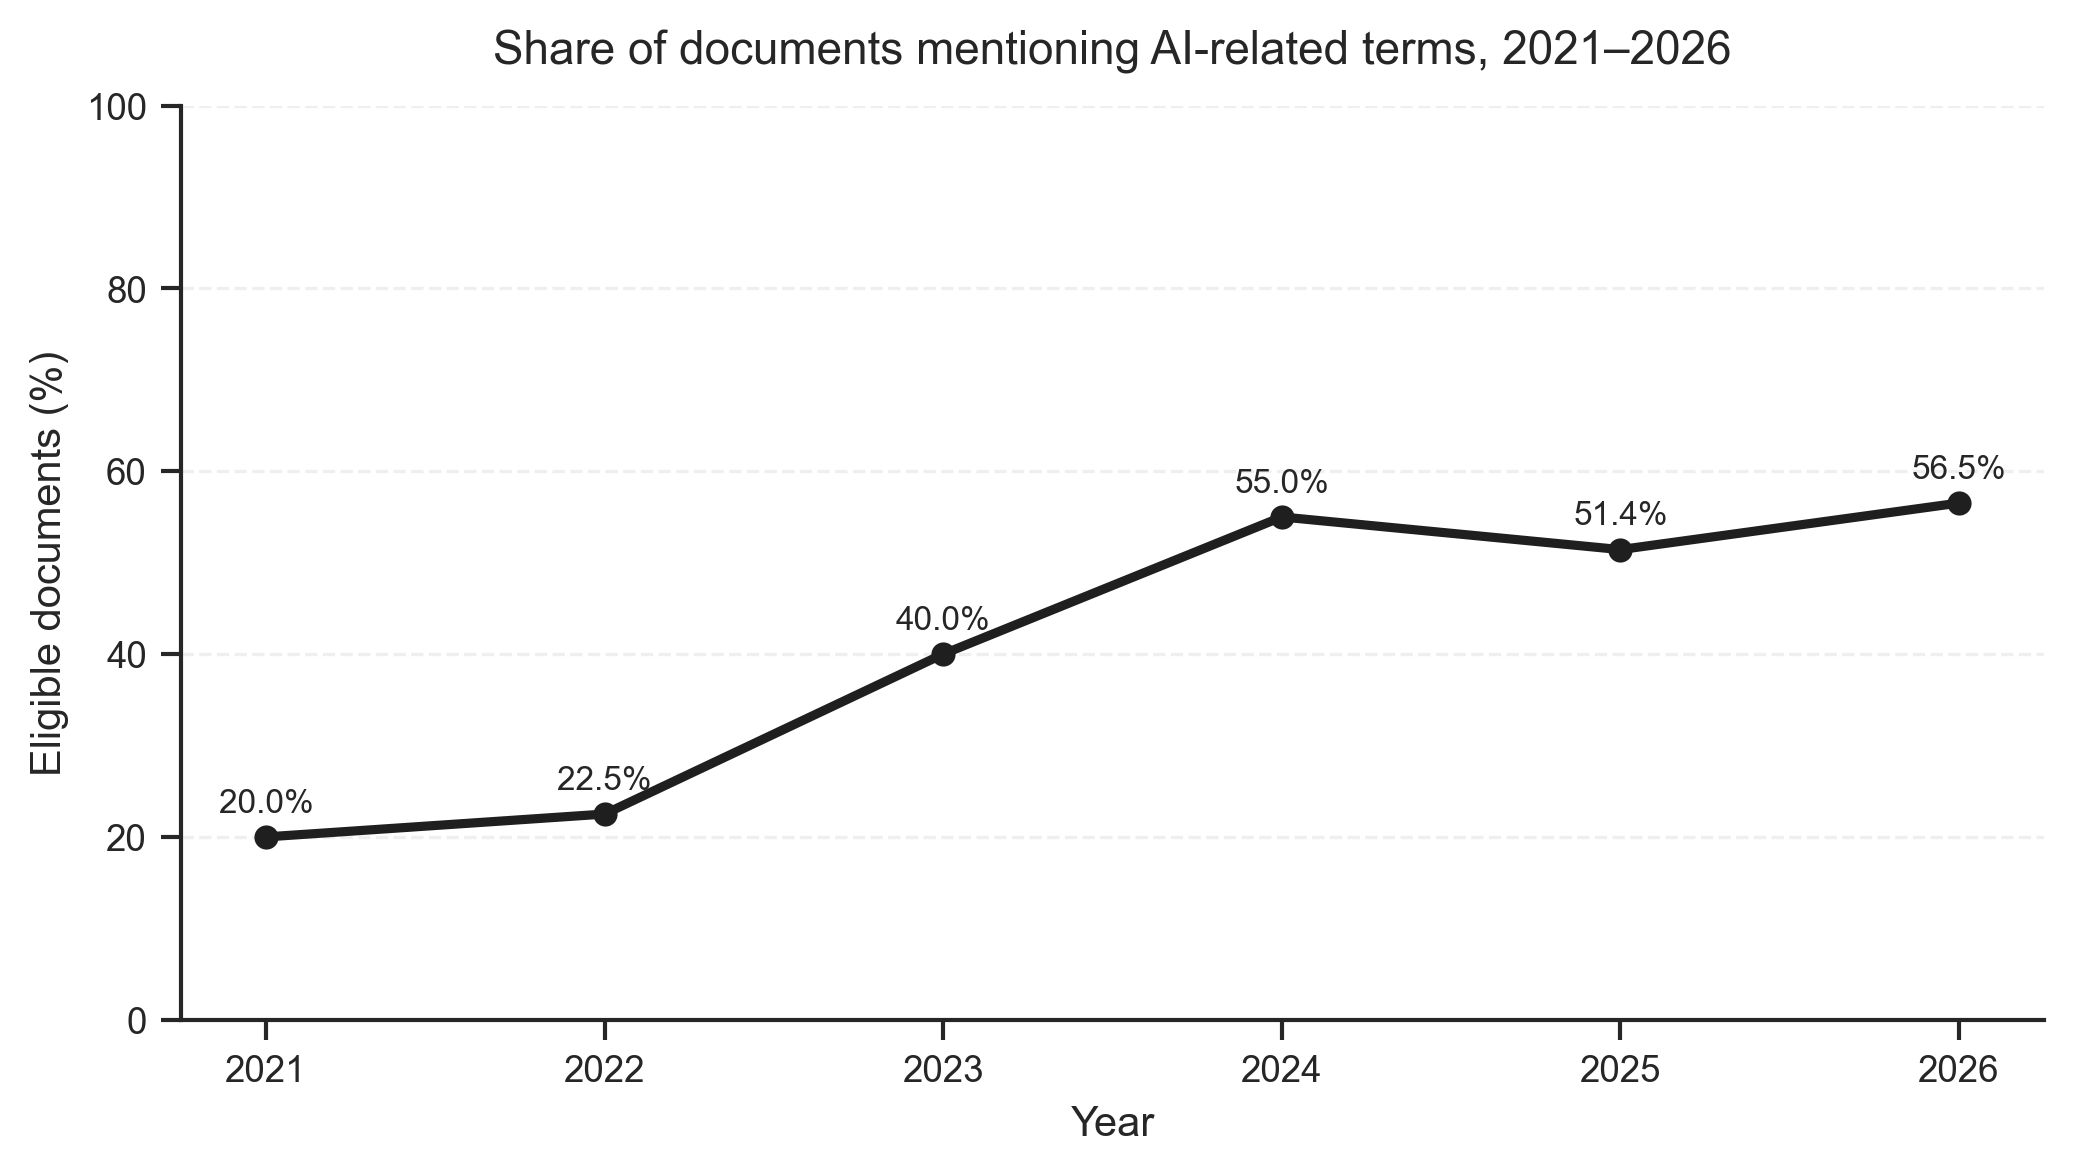

In [11]:
plot_df = overall_year.copy()
plot_df = plot_df.sort_values('year')

sns.set_theme(style='ticks', context='paper')
fig, ax = plt.subplots(figsize=(7.0, 4.0), dpi=300)

ax.plot(
    plot_df['year'],
    plot_df['eligible_pct'],
    color='#1f1f1f',
    marker='o',
    markersize=4.8,
    linewidth=2.2
    )

for _, r in plot_df.iterrows():
    ax.annotate(
        f"{r['eligible_pct']:.1f}%",
        (r['year'], r['eligible_pct']),
        textcoords='offset points',
        xytext=(0, 6),
        ha='center',
        fontsize=8
    )

ax.set_title('Share of documents mentioning AI-related terms, 2021–2026', fontsize=11, pad=10)
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Eligible documents (%)', fontsize=10)
ax.set_ylim(0, 100)
ax.set_xticks(sorted(plot_df['year'].unique()))
ax.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

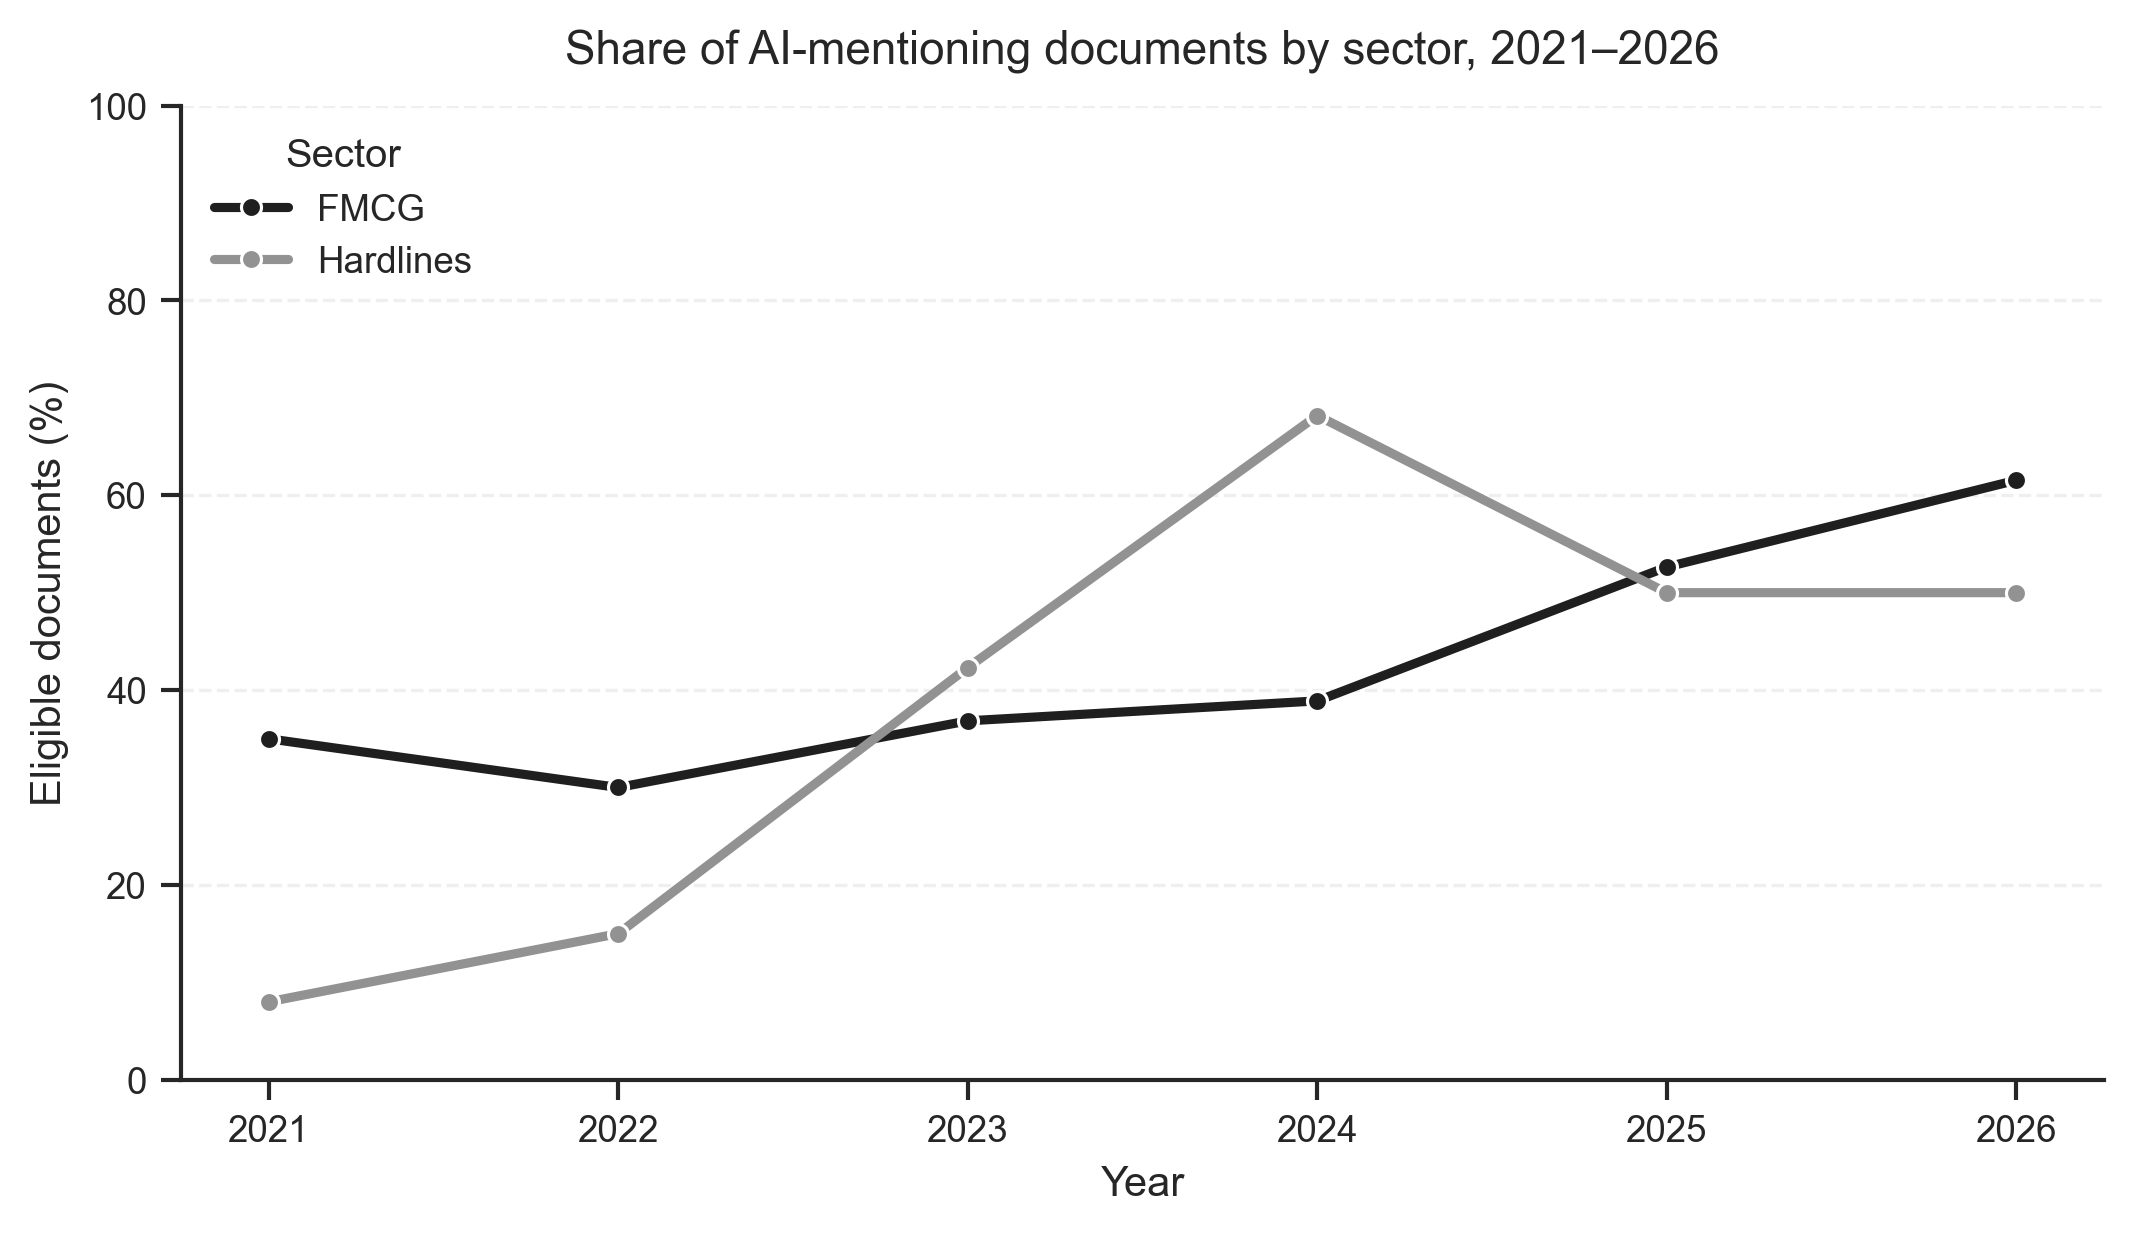

In [12]:
sector_plot = sector_year.copy().sort_values(['sector', 'year'])

sns.set_theme(style='ticks', context='paper')
fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=300)

sns.lineplot(
    data=sector_plot,
    x='year',
    y='eligible_pct',
    hue='sector',
    marker='o',
    linewidth=2.2,
    palette=['#1f1f1f', "#939292"],
    ax=ax
    )

ax.set_title('Share of AI-mentioning documents by sector, 2021–2026', fontsize=11, pad=10)
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Eligible documents (%)', fontsize=10)
ax.set_ylim(0, 100)
ax.set_xticks(sorted(sector_plot['year'].unique()))
ax.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine(ax=ax)
ax.legend(title='Sector', frameon=False, loc='upper left')

plt.tight_layout()
plt.show()

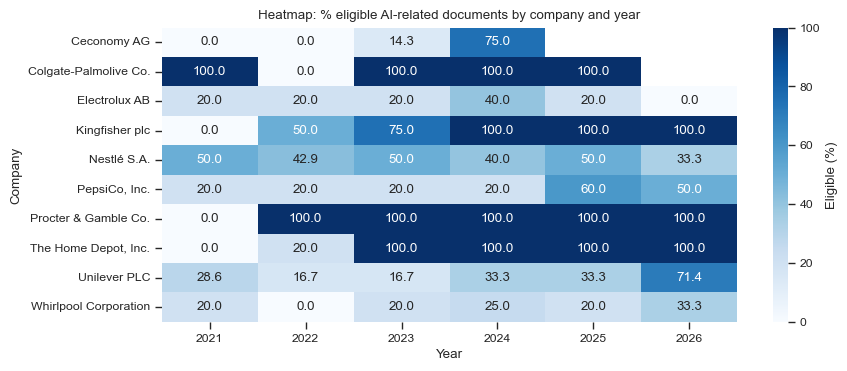

In [13]:
heat = company_year.pivot(index='company', columns='year', values='eligible_pct').sort_index()

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': 'Eligible (%)'}, ax=ax)
ax.set_title('Heatmap: % eligible AI-related documents by company and year')
ax.set_xlabel('Year')
ax.set_ylabel('Company')
plt.tight_layout()
plt.show()

## Analytical/Predictive vs Generative/Agentic AI section

This section applies a dual seed-dictionary to split eligible documents into two narrative families:

- **Analytical/Predictive AI** (e.g., machine learning, neural networks, demand forecasting, algorithmic scheduling)
- **Generative/Agentic AI** (e.g., LLMs, generative AI, copilot, autonomous workflows)

A document can belong to both families if both term groups are present.

In [14]:
dual_df = df_docs.copy()
dual_df['ai_class'] = np.select(
    [
        dual_df['legacy_predictive_eligible'] & dual_df['generative_agentic_eligible'],
        dual_df['legacy_predictive_eligible'] & ~dual_df['generative_agentic_eligible'],
        ~dual_df['legacy_predictive_eligible'] & dual_df['generative_agentic_eligible'],
    ],
    [
        'Both',
        'Analytical/Predictive AI',
        'Generative/Agentic AI'
    ],
    default='Not classifiable'
    )

class_order = [
    'Analytical/Predictive AI',
    'Generative/Agentic AI',
    'Both',
    'Not classifiable'
    ]


In [15]:
class_year = (
    dual_df.groupby(['year', 'ai_class'], as_index=False)
           .size()
           .rename(columns={'size': 'doc_count'})
)

all_years = sorted(dual_df['year'].unique())
class_year = (
    class_year.set_index(['year', 'ai_class'])
              .reindex(pd.MultiIndex.from_product([all_years, class_order], names=['year', 'ai_class']), fill_value=0)
              .reset_index()
 )

year_totals = class_year.groupby('year', as_index=False)['doc_count'].sum().rename(columns={'doc_count': 'total_docs'})
class_year = class_year.merge(year_totals, on='year', how='left')
class_year['doc_pct'] = 100 * class_year['doc_count'] / class_year['total_docs']

class_sector_year = (
    dual_df.groupby(['sector', 'year', 'ai_class'], as_index=False)
           .size()
           .rename(columns={'size': 'doc_count'})
)

all_sectors = sorted(dual_df['sector'].unique())
class_sector_year = (
    class_sector_year.set_index(['sector', 'year', 'ai_class'])
                    .reindex(
                        pd.MultiIndex.from_product([all_sectors, all_years, class_order], names=['sector', 'year', 'ai_class']),
                        fill_value=0
                    )
                    .reset_index()
 )

sector_totals = class_sector_year.groupby(['sector', 'year'], as_index=False)['doc_count'].sum().rename(columns={'doc_count': 'total_docs'})
class_sector_year = class_sector_year.merge(sector_totals, on=['sector', 'year'], how='left')
class_sector_year['doc_pct'] = np.where(
    class_sector_year['total_docs'] > 0,
    100 * class_sector_year['doc_count'] / class_sector_year['total_docs'],
    np.nan
)

class_year.head()

,year,ai_class,doc_count,total_docs,doc_pct
0,2021,Analytical/Predictive AI,18,45,40.0
1,2021,Generative/Agentic AI,0,45,0.0
2,2021,Both,0,45,0.0
3,2021,Not classifiable,27,45,60.0
4,2022,Analytical/Predictive AI,17,40,42.5


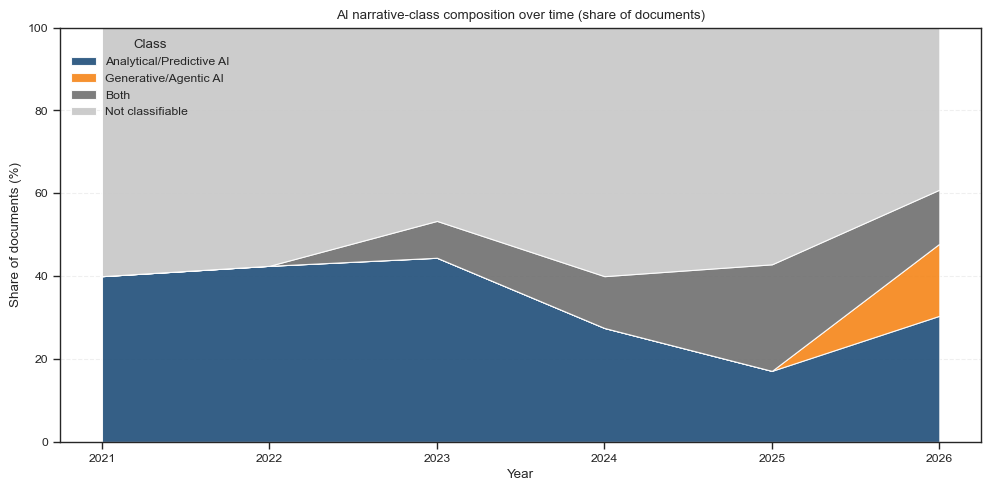

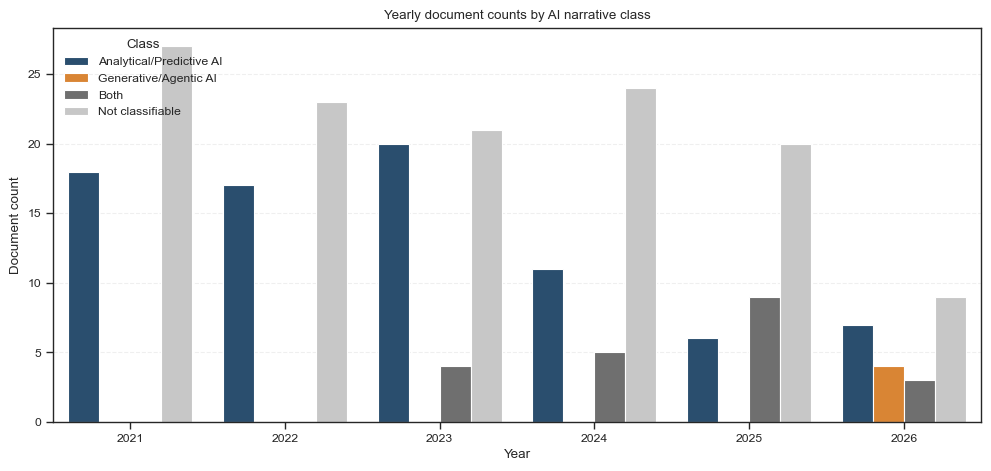

In [16]:
area_df = class_year.pivot(index='year', columns='ai_class', values='doc_pct').reindex(columns=class_order).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#1f4e79', '#f58518', '#6f6f6f', '#c7c7c7']
ax.stackplot(
    area_df.index,
    [area_df[c] for c in class_order],
    labels=class_order,
    colors=colors,
    alpha=0.9
 )
ax.set_title('AI narrative-class composition over time (share of documents)')
ax.set_xlabel('Year')
ax.set_ylabel('Share of documents (%)')
ax.set_ylim(0, 100)
ax.legend(title='Class', frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(
    data=class_year,
    x='year',
    y='doc_count',
    hue='ai_class',
    hue_order=class_order,
    palette=colors,
    ax=ax
 )
ax.set_title('Yearly document counts by AI narrative class')
ax.set_xlabel('Year')
ax.set_ylabel('Document count')
ax.legend(title='Class', frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

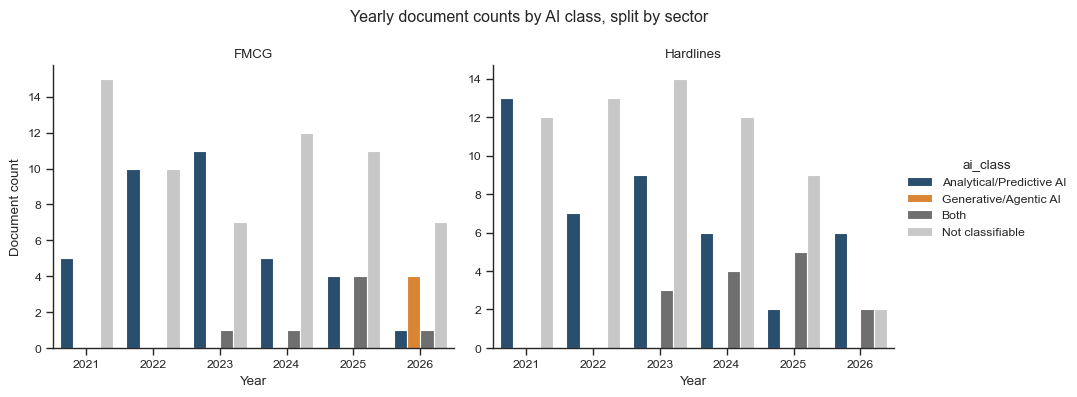

,sector,year,ai_class,doc_count,total_docs,doc_pct
0,FMCG,2021,Analytical/Predictive AI,5,20,25.0
1,FMCG,2021,Generative/Agentic AI,0,20,0.0
2,FMCG,2021,Both,0,20,0.0
3,FMCG,2021,Not classifiable,15,20,75.0
4,FMCG,2022,Analytical/Predictive AI,10,20,50.0


In [17]:
g = sns.catplot(
    data=class_sector_year,
    x='year', y='doc_count',
    hue='ai_class',
    hue_order=class_order,
    col='sector',
    kind='bar',
    palette=['#1f4e79', '#f58518', '#6f6f6f', '#c7c7c7'],
    height=4, aspect=1.15,
    sharey=False
 )
g.set_axis_labels('Year', 'Document count')
g.set_titles('{col_name}')
g.fig.subplots_adjust(top=0.84)
g.fig.suptitle('Yearly document counts by AI class, split by sector')
plt.show()

class_sector_year.head()

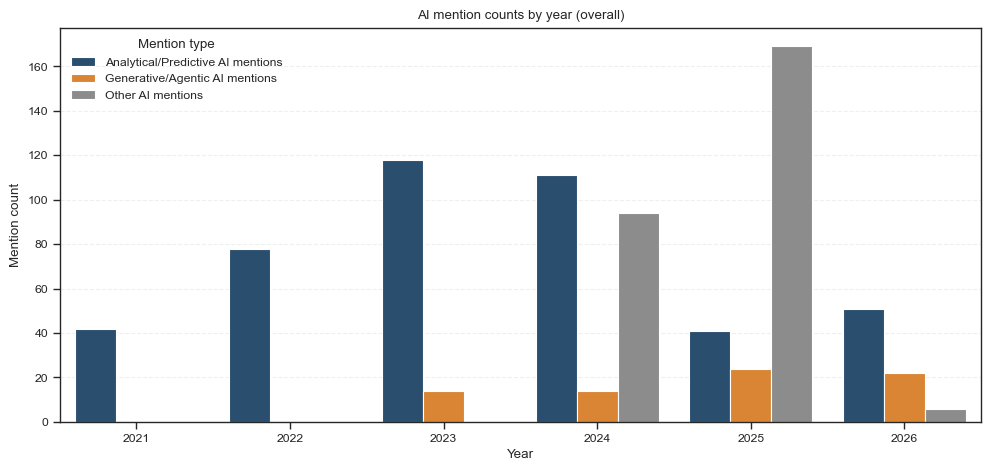

In [18]:
mention_year = (
    df_docs.groupby('year', as_index=False)
    .agg(
        analytical_predictive_mentions=('legacy_predictive_mentions', 'sum'),
        generative_agentic_mentions=('generative_agentic_mentions', 'sum'),
        total_ai_mentions=('total_ai_mentions', 'sum')
    )
)
mention_year['other_ai_mentions'] = (
    mention_year['total_ai_mentions']
    - mention_year['analytical_predictive_mentions']
    - mention_year['generative_agentic_mentions']
).clip(lower=0)

mention_year_long = mention_year.melt(
    id_vars=['year'],
    value_vars=['analytical_predictive_mentions', 'generative_agentic_mentions', 'other_ai_mentions'],
    var_name='mention_type',
    value_name='mention_count'
 )
mention_type_map = {
    'analytical_predictive_mentions': 'Analytical/Predictive AI mentions',
    'generative_agentic_mentions': 'Generative/Agentic AI mentions',
    'other_ai_mentions': 'Other AI mentions'
}
mention_year_long['mention_type'] = mention_year_long['mention_type'].map(mention_type_map)

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(
    data=mention_year_long,
    x='year',
    y='mention_count',
    hue='mention_type',
    palette=['#1f4e79', '#f58518', '#8c8c8c'],
    ax=ax
 )
ax.set_title('AI mention counts by year (overall)')
ax.set_xlabel('Year')
ax.set_ylabel('Mention count')
ax.legend(title='Mention type', frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

## AI Narrative Exposure Index (AIE)

To normalize for document volume, we compute exposure as term occurrences per 10,000 words at the firm-year level:

$$AIE_{it}=\frac{\sum \text{AI term occurrences}_{it}}{\sum \text{words}_{it}}\times 10{,}000$$

where $i$ is firm and $t$ is reporting period (year).

The same normalization is also reported separately for:
- Legacy/Predictive AI exposure
- Generative/Agentic AI exposure

In [19]:
aie_firm_year = (
    df_docs.groupby(['company', 'year'], as_index=False)
    .agg(
        total_docs=('path', 'count'),
        total_words=('word_count', 'sum'),
        total_ai_mentions=('total_ai_mentions', 'sum'),
        legacy_mentions=('legacy_predictive_mentions', 'sum'),
        genagentic_mentions=('generative_agentic_mentions', 'sum')
    )
)

aie_firm_year['AIE_it'] = np.where(
    aie_firm_year['total_words'] > 0,
    10000 * aie_firm_year['total_ai_mentions'] / aie_firm_year['total_words'],
    np.nan
)
aie_firm_year['AIE_legacy_it'] = np.where(
    aie_firm_year['total_words'] > 0,
    10000 * aie_firm_year['legacy_mentions'] / aie_firm_year['total_words'],
    np.nan
)
aie_firm_year['AIE_genagentic_it'] = np.where(
    aie_firm_year['total_words'] > 0,
    10000 * aie_firm_year['genagentic_mentions'] / aie_firm_year['total_words'],
    np.nan
)

aie_firm_year = aie_firm_year.sort_values(['company', 'year'])

OUT_AIE = ROOT / 'data' / 'ai_narrative_exposure_index_firm_year.csv'
aie_firm_year.to_csv(OUT_AIE, index=False)


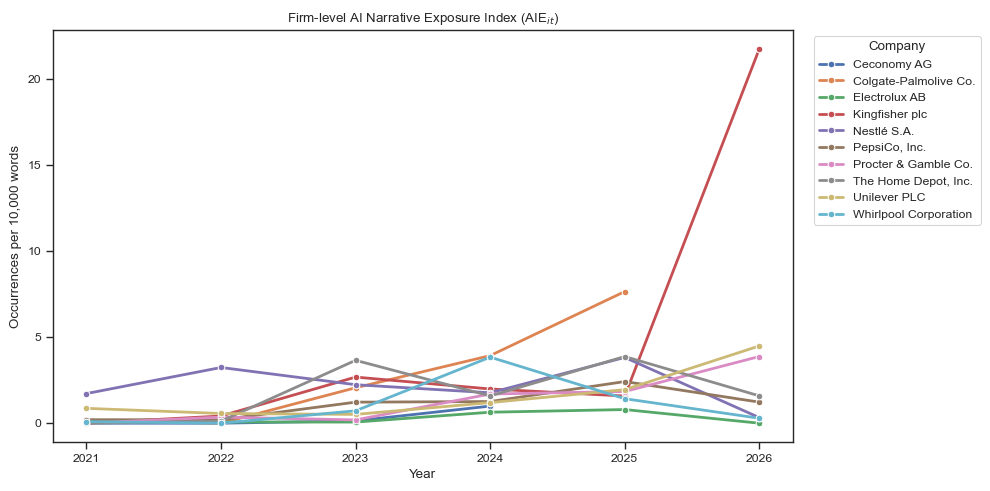

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=aie_firm_year,
    x='year',
    y='AIE_it',
    hue='company',
    marker='o',
    linewidth=2,
    ax=ax
    )
ax.set_title('Firm-level AI Narrative Exposure Index (AIE$_{it}$)')
ax.set_xlabel('Year')
ax.set_ylabel('Occurrences per 10,000 words')
ax.legend(title='Company', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

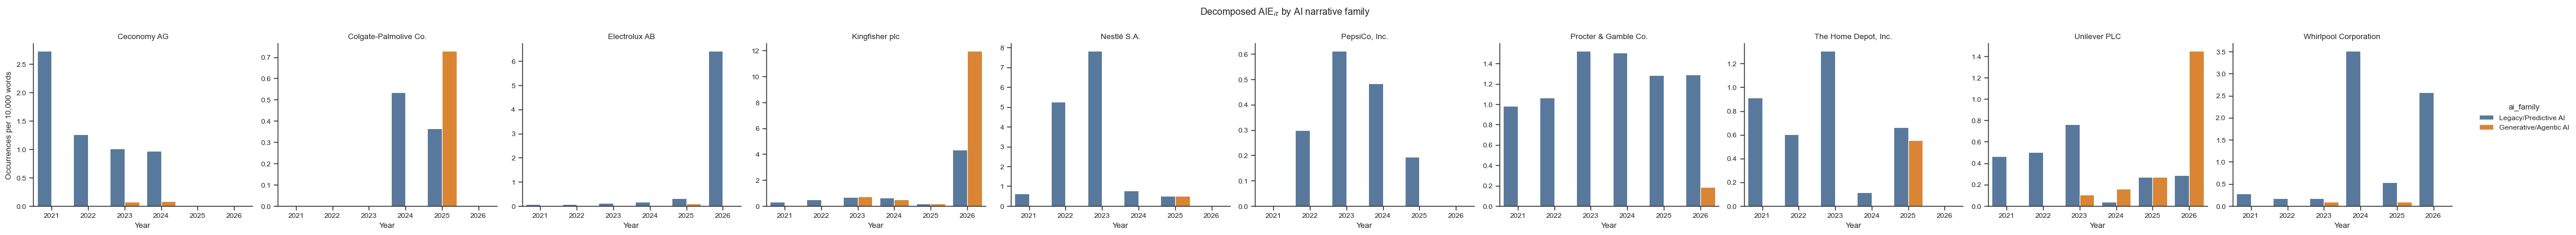

In [21]:
aie_family_long = aie_firm_year.melt(
    id_vars=['company', 'year'],
    value_vars=['AIE_legacy_it', 'AIE_genagentic_it'],
    var_name='ai_family',
    value_name='aie_per_10k'
    )
aie_family_long['ai_family'] = aie_family_long['ai_family'].map({
    'AIE_legacy_it': 'Legacy/Predictive AI',
    'AIE_genagentic_it': 'Generative/Agentic AI'
})

g = sns.catplot(
    data=aie_family_long,
    x='year', y='aie_per_10k',
    hue='ai_family',
    col='company',
    kind='bar',
    palette=['#4C78A8', '#F58518'],
    height=4, aspect=1.05,
    sharey=False
    )
g.set_axis_labels('Year', 'Occurrences per 10,000 words')
g.set_titles('{col_name}')
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Decomposed AIE$_{it}$ by AI narrative family')
plt.show()

/var/folders/dq/fgp118jd64571hh4r6gbvh4w0000gn/T/ipykernel_70843/1945439587.py:39: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.lineplot(


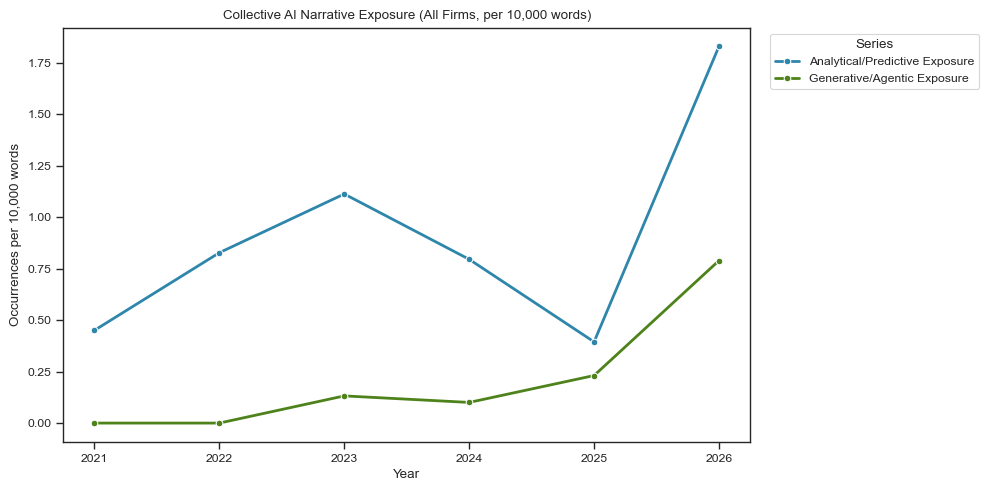

,year,total_words,total_ai_mentions,legacy_mentions,genagentic_mentions,AIE_t,AIE_legacy_t,AIE_genagentic_t
0,2021,932560,33,42,0,0.353865,0.450373,0.000000
1,2022,942632,47,78,0,0.498604,0.827470,0.000000
2,2023,1060649,112,118,14,1.055957,1.112526,0.131995
3,2024,1395664,219,111,14,1.569146,0.795320,0.100311
4,2025,1039540,234,41,24,2.250996,0.394405,0.230871
5,2026,278769,79,51,22,2.833888,1.829472,0.789184


In [22]:
aie_overall_year = (
    df_docs.groupby('year', as_index=False)
    .agg(
        total_words=('word_count', 'sum'),
        total_ai_mentions=('total_ai_mentions', 'sum'),
        legacy_mentions=('legacy_predictive_mentions', 'sum'),
        genagentic_mentions=('generative_agentic_mentions', 'sum')
    )
)

aie_overall_year['AIE_t'] = np.where(
    aie_overall_year['total_words'] > 0,
    10000 * aie_overall_year['total_ai_mentions'] / aie_overall_year['total_words'],
    np.nan
)
aie_overall_year['AIE_legacy_t'] = np.where(
    aie_overall_year['total_words'] > 0,
    10000 * aie_overall_year['legacy_mentions'] / aie_overall_year['total_words'],
    np.nan
)
aie_overall_year['AIE_genagentic_t'] = np.where(
    aie_overall_year['total_words'] > 0,
    10000 * aie_overall_year['genagentic_mentions'] / aie_overall_year['total_words'],
    np.nan
)

aie_overall_long = aie_overall_year.melt(
    id_vars=['year'],
    value_vars=['AIE_t', 'AIE_legacy_t', 'AIE_genagentic_t'],
    var_name='series',
    value_name='aie_per_10k'
    )
aie_overall_long['series'] = aie_overall_long['series'].map({
    'AIE_legacy_t': 'Analytical/Predictive Exposure',
    'AIE_genagentic_t': 'Generative/Agentic Exposure'
})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=aie_overall_long,
    x='year',
    y='aie_per_10k',
    hue='series',
    marker='o',
    linewidth=2,
    palette=['#2E86AB', "#4E821A", '#F58518'],
    ax=ax
    )
ax.set_title('Collective AI Narrative Exposure (All Firms, per 10,000 words)')
ax.set_xlabel('Year')
ax.set_ylabel('Occurrences per 10,000 words')
ax.legend(title='Series', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

aie_overall_year

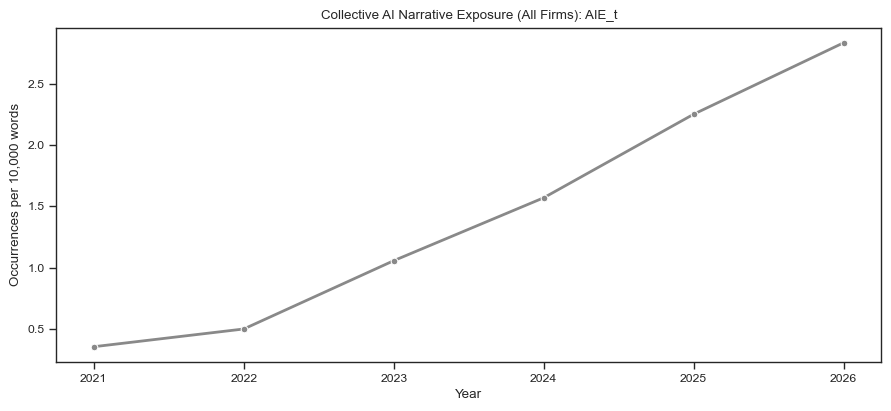

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.lineplot(
data=aie_overall_year,
x='year', y='AIE_t',
marker='o', linewidth=2, color="#898989",
ax=ax
)
ax.set_title('Collective AI Narrative Exposure (All Firms): AIE_t')
ax.set_xlabel('Year')
ax.set_ylabel('Occurrences per 10,000 words')
plt.tight_layout()
plt.show()

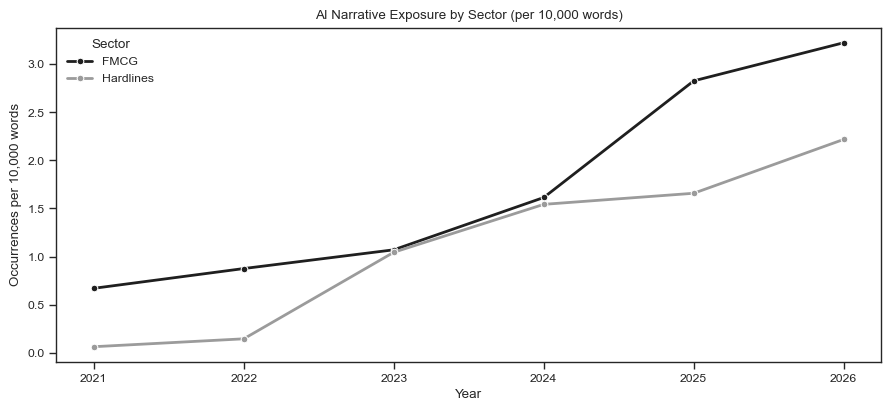

,sector,year,total_words,total_ai_mentions,AIE_st
0,FMCG,2021,448099,30,0.669495
1,FMCG,2022,457089,40,0.875103
2,FMCG,2023,476583,51,1.070118
3,FMCG,2024,514197,83,1.614167
4,FMCG,2025,526960,149,2.827539
5,FMCG,2026,170584,55,3.224218
6,Hardlines,2021,484461,3,0.061924
7,Hardlines,2022,485543,7,0.144168
8,Hardlines,2023,584066,61,1.044403
9,Hardlines,2024,881467,136,1.542882


In [24]:
aie_sector_year = (
    df_docs.groupby(['sector', 'year'], as_index=False)
    .agg(
        total_words=('word_count', 'sum'),
        total_ai_mentions=('total_ai_mentions', 'sum')
    )
)

aie_sector_year['AIE_st'] = np.where(
    aie_sector_year['total_words'] > 0,
    10000 * aie_sector_year['total_ai_mentions'] / aie_sector_year['total_words'],
    np.nan
)

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.lineplot(
    data=aie_sector_year,
    x='year', y='AIE_st',
    hue='sector',
    marker='o', linewidth=2,
    palette=['#1f1f1f', "#9B9B9B"],
    ax=ax
    )
ax.set_title('AI Narrative Exposure by Sector (per 10,000 words)')
ax.set_xlabel('Year')
ax.set_ylabel('Occurrences per 10,000 words')
ax.legend(title='Sector', frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

aie_sector_year